Flusso di Poiseuille MFN

In [ ]:
# @markdown Importazione delle librerie
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F # per la definizione di GELU modificata
from torch.optim import Adam # l'ottimizzatore

import matplotlib.pyplot as plt

import time
from tqdm.auto import tqdm  # barra di avanzamento per le epoche

SEED = 1234
print(f"SEED={SEED}")
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device in uso: {device}")
torch.set_float32_matmul_precision('high') # meno cifre nelle operazioni -> tempi più brevi

SEED=1234
Device in uso: cuda


In [ ]:
# @markdown DEFINIZIONE DELLE VARIABILI ("mostra codice" per cambiare i valori)

# DOMINIO FISICO (tubo)
Lx = 5.
Ly = 1.

# COLLOCATION POINTS PER LE CONDIZIONI AL CONTRONO (DIRICHLET)
N_b = 1000

# IN CASO DI COLLOCATION POINTS FISSATI (modificare il ciclo di traning con i tensori già predisposti invece che con i tensori dati dalla funzione di batching)
N_f = 10000 # collocation points

# IN CASO DI COLLOCATION POINTS NON FISSATI (mini batching)
N_f_batch = 1000

# A SECONDA SE SI FACCIA MINI-BATCHING O MENO BISOGNA CERCARE LE FUNZIONE loss_pde, e commentare la versione non utile, lasciando solo quella utile.

# PARAMETRI FLUIDODINAMICI E VARIABILI AUSILIARIE
# parametri fisici ademensionali
rho = 1.0        # densità
mu  = 0.01       # viscosità dinamica
nu  = mu / rho   # viscosità cinematica

# velocità = 1 sulle x, ed = 0 sulle y
U_inlet = 1.    # componente velocità sulle x imposta in ingresso, al massimo (profilo parabolico della velocità), si assume velocità nulla ai borrdi per il no-slip
V_inlet = 0.0    # componente v imposta in ingresso (flusso puramente assiale)

# velocità caratteristica e lunghezza caratteristica, per il numero di Reynolds
U_ref = U_inlet      # velocità caratteristica (di inlet)
L_ref = Ly       # lunghezza caratteristica (del canale)

# CONDIZIONI DI DIRICHLET

# # caratteristiche dell'uscita
# U_outlet = 1.0
# V_outlet = 0.0
# condizioni di no-slip alle pareti
U_wall = 0.0
V_wall = 0.0

# COEFFICIENTI DEI TERMINI DELLA LOSS
lambda_continuity = 1.0
lambda_momentum_x = 1.0
lambda_momentum_y = 1.0
lambda_inlet = 1.0
lambda_outlet = 1.0
lambda_walls = 1.0
# per ricavarli si può fare un primo allenamento imponendoli tutti uguali ad 1 e leggere i risultati della penultima cella per correggerli per i prossimi cicli di training

# PARAMETRI DEL MODELLO
in_dim = 2 # numero di grandezze fisiche in entrata (x ed y, senza tempo)
out_dim = 3 # numero di grandezze fisiche in uscita (vx, vy e pressione)
fuorier_mapping_size = 45
hidden_dim = fuorier_mapping_size*2
n_layers = 2               # numero di stratri MFN (modified fuorier network) se impostato a 0 o 1 sarà dato da (FuorierEmbed -> Linear U x Linear V x Linear input -> Hidden layers (non ci sono, non si usano ne U, ne V) -> Linear output)
fuorier_scale = 1.0        # fattore moltiplicativo delle funzioni goniometriche (a.k.a. ampiezza/fattore di scala)

# PARAMETRI DELL'OTTIMIZZATORE E DI LEARNING
lri = 1e-2            # learning rate iniziale
gamma = 0.1           # fattore di moltiplicazione del learnin rate
N_EPOCHS = 6000      # autoesplicativo
step_size = int(N_EPOCHS/3)      # numero di epoche che deve passare prima che lr venga moltiplicato per il fattore gamma
# ottimizzatore adam con


In [ ]:
# @markdown Definizione dei punti di collocazione

# punti di collocazione
def sample_interior(n):
    x = np.random.uniform(0, Lx, (n, 1))
    y = np.random.uniform(0, Ly, (n, 1))
    return x, y

x_f, y_f = sample_interior(N_f)

# punti di ingresso (bordo sinistro, x = 0)
def sample_inlet(n):
    x = np.zeros((n, 1))
    y = np.random.uniform(0, Ly, (n, 1))
    return x, y

x_in, y_in = sample_inlet(N_b)

# punti di uscita (bordo destro, x = Lx)
def sample_outlet(n):
    x = np.full((n, 1), Lx)
    y = np.random.uniform(0, Ly, (n, 1))
    return x, y

x_out, y_out = sample_outlet(N_b)

# punti sulle pareti (y = 0, y = Ly)
# no-slip e condizioni al contorno addizionali
def sample_walls(n):
    x_w = np.random.uniform(0, Lx, (n, 1))
    y_bottom = np.zeros((n, 1))
    y_top    = np.full((n, 1), Ly)
    return x_w, y_bottom, y_top

x_w, y_bottom, y_top = sample_walls(N_b)

#Conversione in tensori torch

# per i prossimi numpy -> tensori si tratta di punti interni
# dobbiamo poter minimzzare la loss, ci servono le derivate
X_f = torch.tensor(x_f, dtype=torch.float32, requires_grad=True).to(device)
Y_f = torch.tensor(y_f, dtype=torch.float32, requires_grad=True).to(device)

# per i prossimi punti si tratta di punti ausiliari dove imporre condizioni
# al contorno, che non cambiano e che non riguardano navier-stokes, non serve
# poter calcolare il gradiente
X_in = torch.tensor(x_in, dtype=torch.float32, requires_grad=False).to(device)
Y_in = torch.tensor(y_in, dtype=torch.float32, requires_grad=False).to(device)

X_out = torch.tensor(x_out, dtype=torch.float32, requires_grad=True).to(device)
Y_out = torch.tensor(y_out, dtype=torch.float32, requires_grad=True).to(device)

X_w = torch.tensor(x_w, dtype=torch.float32, requires_grad=False).to(device)
Y_bottom = torch.tensor(y_bottom, dtype=torch.float32, requires_grad=False).to(device)
Y_top = torch.tensor(y_top, dtype=torch.float32, requires_grad=False).to(device)

print(f"Punti interni:  {X_f.shape[0]}")
print(f"Punti inlet:    {X_in.shape[0]}")
print(f"Punti outlet:   {X_out.shape[0]}")
print(f"Punti pareti:   {X_w.shape[0]} (top+bottom)")

Punti interni:  10000
Punti inlet:    1000
Punti outlet:   1000
Punti pareti:   1000 (top+bottom)


In [ ]:
# @markdown Calcolo dei parametri fluidodinamici

# numero di Reynolds
Re = U_ref * L_ref / nu
print(f"Numero di Reynolds: Re = {Re:.2f}")

# coefficiente di viscosità per le eq. adimensionali
inv_Re = 1.0 / Re

print(f"rho = {rho}, mu = {mu}, nu = {nu:.5f}")
print(f"1/Re = {inv_Re:.5f}")

Numero di Reynolds: Re = 100.00
rho = 1.0, mu = 0.01, nu = 0.01000
1/Re = 0.01000


In [ ]:
# @markdown Implementazione di N-S 2D, condizioni al bordo e delle Loss in generale ("mostra codice per modificare le loss")

# funzione di passaggio, prende il modello
# restituisce u, v (velocità sulle x, velocità sulle y) e p (pressione)
# per un batch di punti (x, y)

def net_uvp(model, x, y):   # non dipentente dal tempo (per problemi stazionari fa risparmiare molto tempo di calcolo)
    inputs = torch.cat([x, y], dim=1)
    out = model(inputs)
    return out[:, 0:1], out[:, 1:2], out[:, 2:3]


# residuo delle equazioni di navier-stokes 2D, da usare poi nella loss
# incomprimibili, adimensionali, nei punti interni, costante nel tempo
def navier_stokes_residual(model, x, y, inv_Re):
    u, v, p = net_uvp(model, x, y)
    ones_u, ones_v, ones_p = torch.ones_like(u), torch.ones_like(v), torch.ones_like(p)

    u_x, u_y = torch.autograd.grad(u, [x, y], grad_outputs=ones_u, create_graph=True)
    v_x, v_y = torch.autograd.grad(v, [x, y], grad_outputs=ones_v, create_graph=True)
    p_x, p_y = torch.autograd.grad(p, [x, y], grad_outputs=ones_p, create_graph=True)

    u_xx = torch.autograd.grad(u_x, x, grad_outputs=ones_u, create_graph=True)[0]
    u_yy = torch.autograd.grad(u_y, y, grad_outputs=ones_u, create_graph=True)[0]
    v_xx = torch.autograd.grad(v_x, x, grad_outputs=ones_v, create_graph=True)[0]
    v_yy = torch.autograd.grad(v_y, y, grad_outputs=ones_v, create_graph=True)[0]

    continuity = u_x + v_y
    momentum_x = u * u_x + v * u_y + p_x - inv_Re * (u_xx + u_yy)  # niente u_t
    momentum_y = u * v_x + v * v_y + p_y - inv_Re * (v_xx + v_yy)  # niente v_t

    return continuity, momentum_x, momentum_y

# versione per poseuille, senza tempo, utile per mini-batching
def loss_pde(model, x, y):
    continuity, momentum_x, momentum_y = navier_stokes_residual(model, x, y, inv_Re)
    mse_continuity = torch.mean(continuity**2)
    mse_momentum_x = torch.mean(momentum_x**2)
    mse_momentum_y = torch.mean(momentum_y**2)
    return mse_continuity, mse_momentum_x, mse_momentum_y


def poiseuille_profile(y, U_inlet, Ly):
    """Profilo parabolico: 0 alle pareti, U_inlet al centro."""
    return 4 * U_inlet * y * (Ly - y) / (Ly**2)

# lo implementiamo in una funzione sola per risparmiare sulle chiamate, senza tempo
def loss_boundaries(model):
    # concatena TUTTI i punti di bordo in un unico batch
    x_all = torch.cat([X_in, X_out, X_w, X_w], dim=0)
    y_all = torch.cat([Y_in, Y_out, Y_bottom, Y_top], dim=0)

    u_all, v_all, p_all = net_uvp(model, x_all, y_all)

    n = N_b
    u_in, v_in       = u_all[0:n],     v_all[0:n]
    u_out, v_out, p_out   = u_all[n:2*n],   v_all[n:2*n], p_all[n:2*n]
    u_bot, v_bot     = u_all[2*n:3*n], v_all[2*n:3*n]
    u_top, v_top     = u_all[3*n:4*n], v_all[3*n:4*n]

    ones_u = torch.ones_like(u_out)
    ones_v = torch.ones_like(v_out)

    u_x = torch.autograd.grad(u_out, X_out, grad_outputs=ones_u, create_graph=True)[0]
    v_x = torch.autograd.grad(v_out, X_out, grad_outputs=ones_v, create_graph=True)[0]
    target_u_in = poiseuille_profile(Y_in, U_inlet, Ly) #in caso si voglia fare il poiseuille sviluppato
    # target_u_in = torch.full_like(u_in, U_inlet)
    l_in   = torch.mean((u_in - target_u_in)**2) + torch.mean(v_in**2)
    # implementiamo condizioni al contorno sul bordo destro del tubo sul campo della velocità
    l_out  = torch.mean(p_out**2) + torch.mean(u_x**2) + torch.mean(v_x**2)
    l_wall = torch.mean(u_bot**2) + torch.mean(v_bot**2) + torch.mean(u_top**2) + torch.mean(v_top**2)

    return l_in, l_out, l_wall


# loss totale = comb. lineare delle loss precedenti

# ridefiniamo la loss totale in modo che si adegui al mini-batching e sia stazionaria
def total_loss(model, x_f, y_f #, t_f
               ):
    mse_continuity, mse_momentum_x, mse_momentum_y = loss_pde(model, x_f, y_f)
    l_in, l_out, l_wall = loss_boundaries(model)

    loss = (lambda_continuity * mse_continuity +
            lambda_momentum_x * mse_momentum_x +
            lambda_momentum_y * mse_momentum_y +
            lambda_inlet      * l_in +
            lambda_outlet     * l_out +
            lambda_walls      * l_wall)

    components = {
        "continuity": mse_continuity.detach(),
        "momentum_x": mse_momentum_x.detach(),
        "momentum_y": mse_momentum_y.detach(),
        "inlet": l_in.detach(),
        "outlet": l_out.detach(),
        "walls": l_wall.detach(),
        "total": loss.detach()
    }
    return loss, components

In [ ]:
# @markdown Definizione della rete neurale (Modified Fourier Network)

class AdaptiveGELU(nn.Module):
    """GELU con parametro apprendibile (adaptive activation)."""
    def __init__(self):
        super().__init__()
        # parametro inizializzato a 1.0, come un GELU vanilla
        self.alpha = nn.Parameter(torch.tensor(1.0))

    def forward(self, x):
        return F.gelu(self.alpha * x)


class FourierEmbedding(nn.Module):
    """
    Embedding di Fourier per gli input (x, y).
    Mappa l'input in [sin(2*pi*B*z), cos(2*pi*B*z)], con B estratta una sola volta
    da N(0, scale^2) e tenuta FISSA durante l'allenamento (come in Wang et al., 2021).
    """
    def __init__(self, in_dim, mapping_size, scale=1.): # potrebbe essere saggio aggiornarlo a 0.5
        super().__init__()
        # matrice di frequenze: estratta una volta, non allenabile (buffer, non Parameter)
        B = torch.randn(in_dim, mapping_size) * scale
        self.register_buffer("B", B)

    def forward(self, x):
        # x: (N, in_dim)
        x_proj = 2 * np.pi * x @ self.B   # matrice degli argomenti dei seni/coseni
        return torch.cat([torch.sin(x_proj), torch.cos(x_proj)], dim=-1) #


class ModifiedFourierNet(nn.Module):
    """
    Modified Fourier Network (Wang et al., 2021) per PINN.
    Input: (x, y) -> Output: (u, v, p)
    """
    def __init__(self, in_dim=3, out_dim=3, hidden_dim=256, n_layers=6,
                 fourier_mapping_size=128, fourier_scale=1.0):
        super().__init__()

        self.fourier = FourierEmbedding(in_dim, fourier_mapping_size, fourier_scale)
        embed_dim = 2 * fourier_mapping_size  # = 2*128 = sin + cos

        # branch gating di x e y, applicati all'embedding
        self.U_layer = nn.Linear(embed_dim, hidden_dim)
        self.V_layer = nn.Linear(embed_dim, hidden_dim)
        self.act_U = AdaptiveGELU()
        self.act_V = AdaptiveGELU()

        # primo layer nascosto (dall'embedding)
        self.input_layer = nn.Linear(embed_dim, hidden_dim)
        self.act_input = AdaptiveGELU()

        # layer nascosti successivi con update "modified"
        self.hidden_layers = nn.ModuleList(
            [nn.Linear(hidden_dim, hidden_dim) for _ in range(n_layers - 1)]
        )
        self.hidden_acts = nn.ModuleList(
            [AdaptiveGELU() for _ in range(n_layers - 1)]
        )

        # layer di output: (u, v, p)
        self.output_layer = nn.Linear(hidden_dim, out_dim)

    def forward(self, x):
        emb = self.fourier(x)                    # incorporamento fourier

        U = self.act_U(self.U_layer(emb))         # due strati lineari prendono l'embed
        V = self.act_V(self.V_layer(emb))         # in argomento e passano per GELU

        H = self.act_input(self.input_layer(emb)) # (N, hidden_dim) "blocco di mezzo" che vede l'embed

        for layer, act in zip(self.hidden_layers, self.hidden_acts):
            Z = act(layer(H))
            H = (1 - Z) * U + Z * V                # update "modificato"

        out = self.output_layer(H)                # (N, 3) -> u, v, p
        return out


# creazione del modello
model = ModifiedFourierNet(
    in_dim=in_dim,
    out_dim=out_dim,
    hidden_dim=hidden_dim,
    n_layers=n_layers,
    fourier_mapping_size=fuorier_mapping_size,
    fourier_scale=fuorier_scale
).to(device)

# conta dei parametri allenabili (B ora non è inclusa, non sono parametri allenabili)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Numero totale di parametri allenabili: {n_params:,}")
print(f"Elementi di B (fissi): {model.fourier.B.numel():,}")
print(model)

Numero totale di parametri allenabili: 33,037
Elementi di B (fissi): 90
ModifiedFourierNet(
  (fourier): FourierEmbedding()
  (U_layer): Linear(in_features=90, out_features=90, bias=True)
  (V_layer): Linear(in_features=90, out_features=90, bias=True)
  (act_U): AdaptiveGELU()
  (act_V): AdaptiveGELU()
  (input_layer): Linear(in_features=90, out_features=90, bias=True)
  (act_input): AdaptiveGELU()
  (hidden_layers): ModuleList(
    (0): Linear(in_features=90, out_features=90, bias=True)
  )
  (hidden_acts): ModuleList(
    (0): AdaptiveGELU()
  )
  (output_layer): Linear(in_features=90, out_features=3, bias=True)
)


In [ ]:
# @markdown Ottimizzatore ADAM (per usare SGD mostrare il codice della cella precedente)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=lri,
    betas=(0.9, 0.999),
    eps=1e-8,
    weight_decay=0.0
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=step_size,
    gamma=gamma
)

print(f"Ottimizzatore Adam")

Ottimizzatore Adam


In [ ]:
# @markdown Preparazione del mini-batching

# ci prepariamo al minibatching con una funzione che trova dei punti randomici all'interno del canale
# vengono sempre valutate le loss su tutti i punti di frontiera del dominio

# questa cella si può commentare in caso si faccia traning a collocation points fissati

def sample_interior_batch(n):
    """Campiona n punti casuali nel dominio (x,y,(senza)t), pronti per autograd."""
    x = torch.rand(n, 1, device=device) * Lx
    y = torch.rand(n, 1, device=device) * Ly
    x.requires_grad_(True)
    y.requires_grad_(True)
    return x, y

In [ ]:
# @markdown TRAINING LOOP ("Mostra codice" per modificare il calcolo della loss e renderlo sui punti desiderati)

component_names = ["total", "continuity", "momentum_x", "momentum_y", "inlet", "outlet", "walls"]

history_gpu = torch.zeros(N_EPOCHS, len(component_names), device=device)

model.train()
start_time = time.time()

pbar = tqdm(range(N_EPOCHS), desc="Training PINN")
for epoch in pbar:
    optimizer.zero_grad()

    #commentare i due comandi che seguono e decommentare quello successivo per avere i punti fissi

    x_batch, y_batch = sample_interior_batch(N_f_batch)
    loss, components = total_loss(model, x_batch, y_batch)

    # loss, components = total_loss(model, X_f, Y_f)


    loss.backward()
    optimizer.step()

    with torch.no_grad():
        for i, key in enumerate(component_names):
            history_gpu[epoch, i] = components[key]

    if epoch % 100 == 0 or epoch == N_EPOCHS - 1:
        pbar.set_postfix({
            "loss": f"{components['total'].item():.4e}",
            "cont": f"{components['continuity'].item():.2e}",
            "mom_x": f"{components['momentum_x'].item():.2e}",
            "mom_y": f"{components['momentum_y'].item():.2e}",
            "in": f"{components['inlet'].item():.2e}",
            "out (p)": f"{components['outlet'].item():.2e}",
            "wall": f"{components['walls'].item():.2e}",
        })

    if epoch % 2000 == 0:
        elapsed = time.time() - start_time
        print(f"[Epoch {epoch:5d}/{N_EPOCHS}] "
              f"loss = {components['total'].item():.6e}  "
              f"(elapsed: {elapsed/60:.1f} min)")

    scheduler.step()

total_time = time.time() - start_time
print(f"\nTraining completato in {total_time/60:.1f} minuti ({total_time/3600:.2f} ore)")

Training PINN:   0%|          | 0/6000 [00:00<?, ?it/s]

[Epoch     0/6000] loss = 3.770390e+00  (elapsed: 0.0 min)
[Epoch  2000/6000] loss = 2.261885e-04  (elapsed: 1.7 min)
[Epoch  4000/6000] loss = 1.072266e-05  (elapsed: 3.3 min)

Training completato in 4.9 minuti (0.08 ore)


In [ ]:
# @markdown Creazione di un vettore da usare per i grafici
#creiamo il vettore history
history_np = history_gpu.cpu().numpy()
history = {key: history_np[:, i] for i, key in enumerate(component_names)}
for key in history.keys():
  print(key)


total
continuity
momentum_x
momentum_y
inlet
outlet
walls


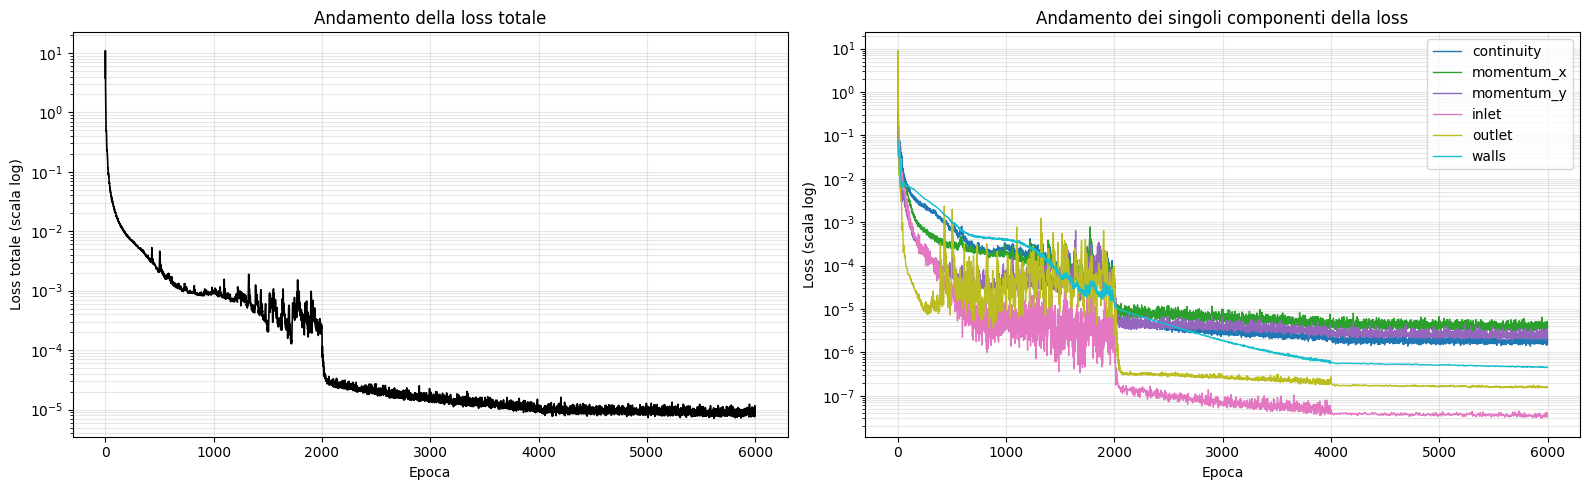

In [ ]:
# @markdown Grafico delle Loss
model.eval()

# PLOT DELLA LOSS (totale e singoli componenti)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

full_component_names = ["total", "continuity", "momentum_x", "momentum_y", "inlet", "outlet", "walls"]
history_np = history_gpu.cpu().numpy()
history = {key: history_np[:, i] for i, key in enumerate(full_component_names)}

epochs_range = np.arange(len(history["continuity"])) # Using 'continuity' as it's guaranteed to be there after the fix

axes[0].plot(epochs_range, history["total"], color="black", linewidth=1.2)
axes[0].set_yscale("log")
axes[0].set_xlabel("Epoca")
axes[0].set_ylabel("Loss totale (scala log)")
axes[0].set_title("Andamento della loss totale")
axes[0].grid(True, which="both", alpha=0.3)

component_names = ["continuity", "momentum_x", "momentum_y", "inlet", "outlet", "walls"]
colors = plt.cm.tab10(np.linspace(0, 1, len(component_names)))

for name, color in zip(component_names, colors):
    axes[1].plot(epochs_range, history[name], label=name, color=color, linewidth=1.0)

axes[1].set_yscale("log")
axes[1].set_xlabel("Epoca")
axes[1].set_ylabel("Loss (scala log)")
axes[1].set_title("Andamento dei singoli componenti della loss")
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

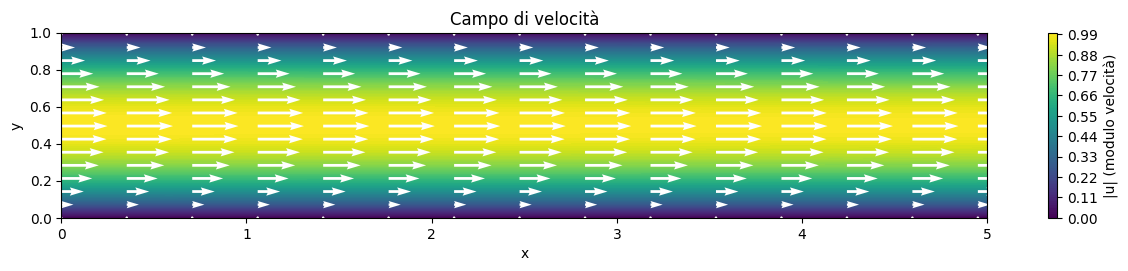

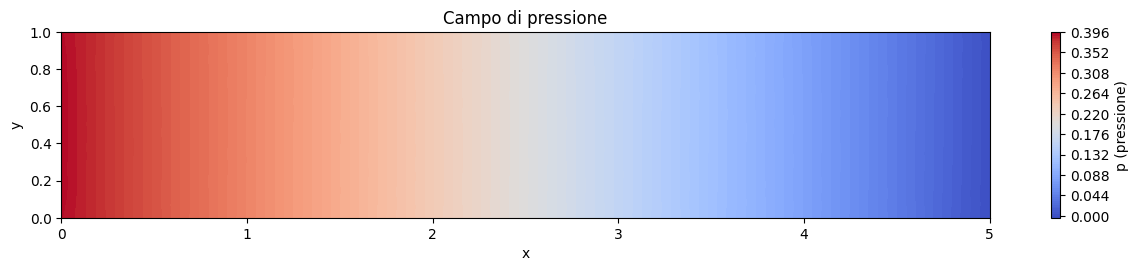

In [ ]:
# @markdown Plot di velocità e pressione

# Superficie colorata secondo il modulo + vettori sovrapposti

def evaluate_velocity_field(model, n_grid=100):
    """Valuta u, v, p su una griglia regolare (x, y) al tempo t_value."""
    x_lin = np.linspace(0, Lx, n_grid)
    y_lin = np.linspace(0, Ly, n_grid)
    X_grid, Y_grid = np.meshgrid(x_lin, y_lin)

    x_flat = X_grid.reshape(-1, 1)
    y_flat = Y_grid.reshape(-1, 1)
    # t_flat = np.full_like(x_flat)

    x_t = torch.tensor(x_flat, dtype=torch.float32).to(device)
    y_t = torch.tensor(y_flat, dtype=torch.float32).to(device)
    # t_t = torch.tensor(t_flat, dtype=torch.float32).to(device)

    with torch.no_grad():
        u, v, p = net_uvp(model, x_t, y_t#, t_t
                          )

    U = u.cpu().numpy().reshape(n_grid, n_grid)
    V = v.cpu().numpy().reshape(n_grid, n_grid)
    P = p.cpu().numpy().reshape(n_grid, n_grid)

    return X_grid, Y_grid, U, V, P


n_grid = 100
quiver_stride = 7  # sottocampiono le frecce per leggibilità

X_grid, Y_grid, U, V, P = evaluate_velocity_field(model, n_grid=n_grid)
speed = np.sqrt(U**2 + V**2)

# plot della velocità
fig_vel, ax_vel = plt.subplots(figsize=(13,2.5))

c = ax_vel.contourf(X_grid, Y_grid, speed, levels=100, cmap="viridis")

ax_vel.quiver(
        X_grid[::quiver_stride, ::quiver_stride],
        Y_grid[::quiver_stride, ::quiver_stride],
        U[::quiver_stride, ::quiver_stride],
        V[::quiver_stride, ::quiver_stride],
        color="white", scale=20, width=0.003
    )

ax_vel.set_title(f"Campo di velocità")
ax_vel.set_xlabel("x")
ax_vel.set_ylabel("y")
ax_vel.set_aspect("equal") # Ensures correct aspect ratio

fig_vel.colorbar(c, ax=ax_vel, label="|u| (modulo velocità)") # Associate colorbar with new figure and axes

plt.tight_layout()
plt.show()

# PLOT DELLA PRESSIONE

fig2, ax2 = plt.subplots(figsize=(13,2.5))

c2 = ax2.contourf(X_grid, Y_grid, P, levels=100, cmap="coolwarm")

ax2.set_title("Campo di pressione")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_aspect("equal")

fig2.colorbar(c2, ax=ax2, label="p (pressione)")

plt.tight_layout()
plt.show()

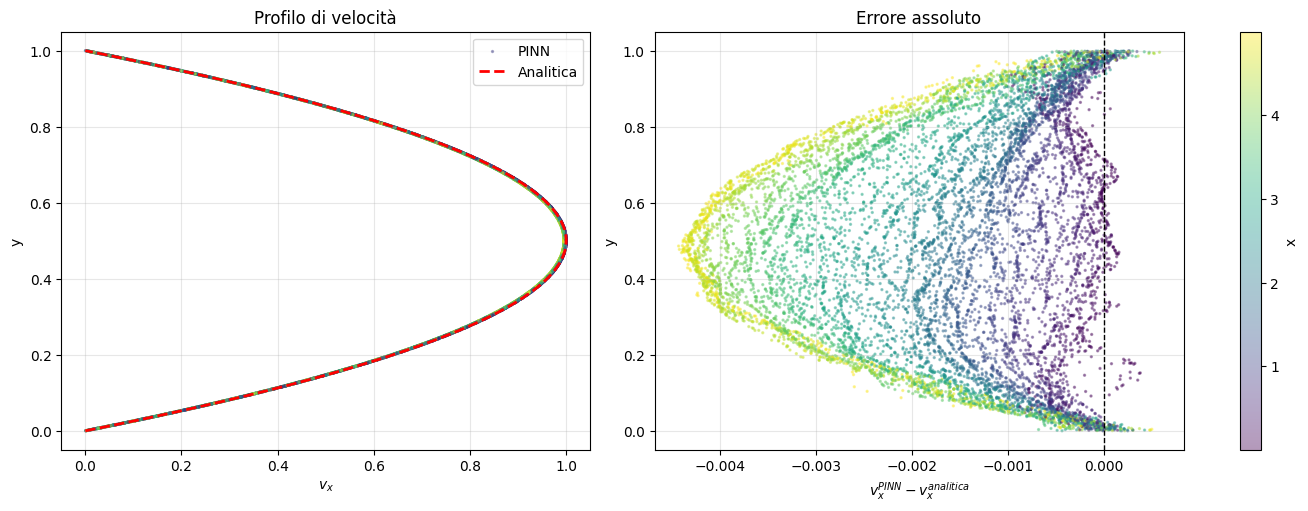

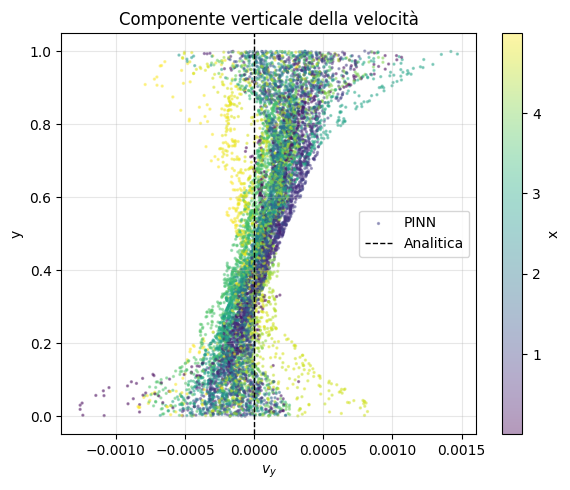

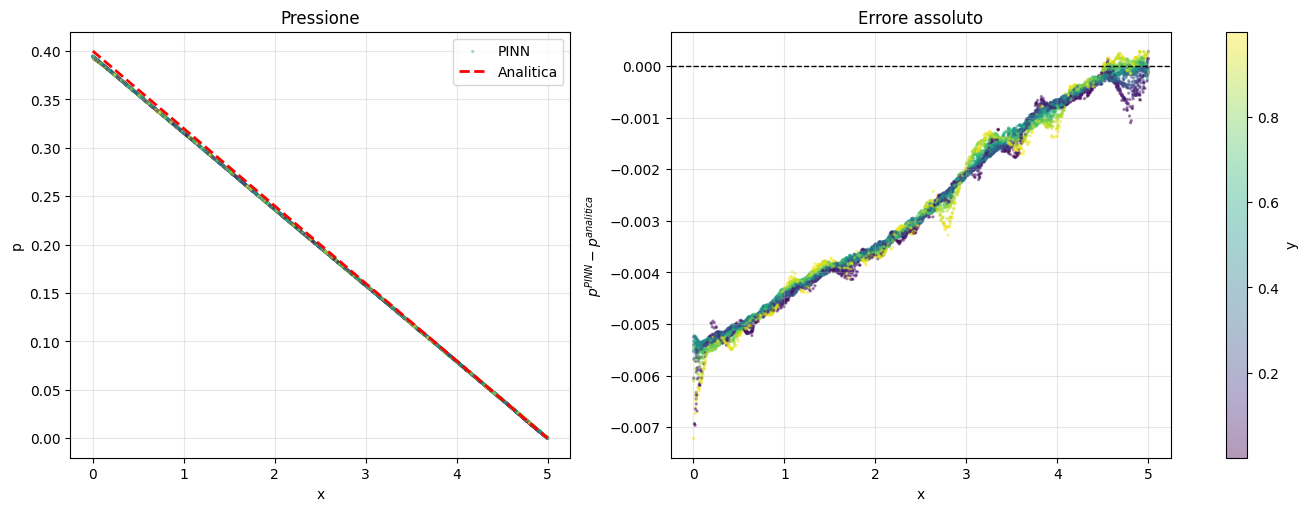

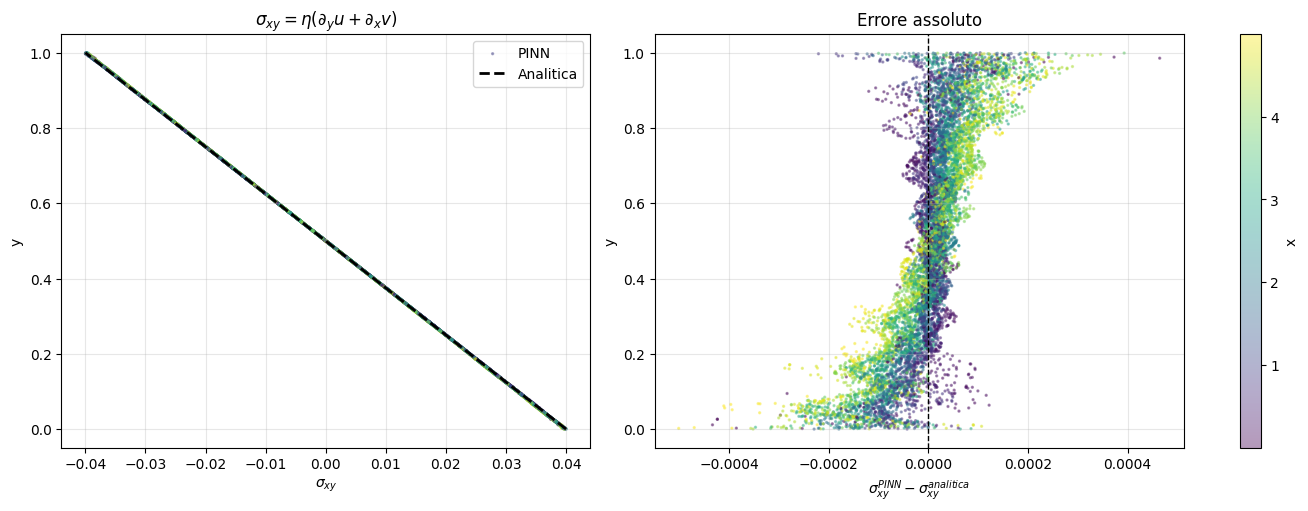

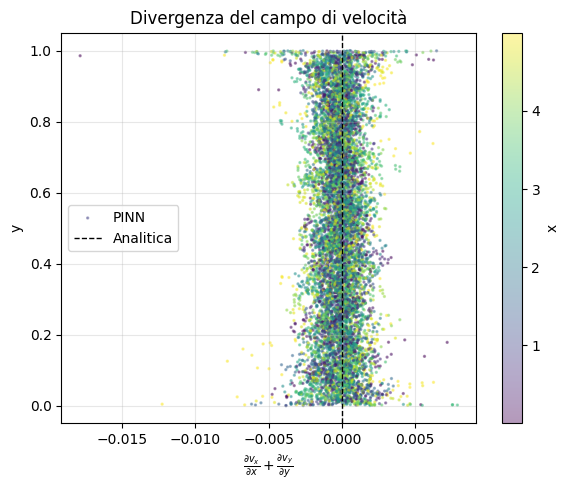

Punti di test: 10000
--------------------------------------------
Errore relativo u:        0.002811 (0.281%)  | max |errore|: 4.432e-03
Errore v (norm. su |u|):  0.000341 (0.034%)  | max |v|:      1.470e-03
Errore relativo p:        0.014025 (1.403%)  | max |errore|: 7.217e-03
Errore relativo sigma_xy: 0.003360 (0.336%)  | max |errore|: 5.009e-04
Errore assoluto continuità: 0.131169
Peso del termine eta*dv/dx su sigma: 1.10e-03


In [ ]:
# @markdown Verifica analitica della soluzione della PINN (u, v, p e $\sigma_{xy}$) sugli stessi punti di test

eta = inv_Re

# punti di test: gli stessi X_f, Y_f usati per la pressione
# (con il mini-batching non entrano mai nel training: fanno da test set indipendente)
x_p = X_f.detach()
y_p = Y_f.detach()
x_p_np = x_p.cpu().numpy().flatten()
y_p_np = y_p.cpu().numpy().flatten()

# soluzioni analitiche
# v = 0 ovunque. p: p_x = (1/Re) u_yy = -8 U / (Re Ly^2), p indipendente da y, p(Lx) = 0
def p_analytical(x):
    return 8 * U_inlet / (Re * Ly**2) * (Lx - x)

def sigma_xy_analytical(y):
    # u = 4 U y (Ly - y) / Ly^2  ->  du/dy = 4 U (Ly - 2y) / Ly^2
    # con U_inlet = 1, eta = 0.01, Ly = 1 diventa 0.04 - 0.08 y
    return eta * 4 * U_inlet * (Ly - 2*y) / Ly**2

def sigma_xy_pinn(model, x, y):
    # servono i gradienti, quindi niente torch.no_grad()
    x = x.clone().requires_grad_(True)
    y = y.clone().requires_grad_(True)
    u, v, _ = net_uvp(model, x, y)
    u_y = torch.autograd.grad(u, y, grad_outputs=torch.ones_like(u), create_graph=False, retain_graph=True)[0]
    v_x = torch.autograd.grad(v, x, grad_outputs=torch.ones_like(v), create_graph=False)[0]
    return eta * (u_y + v_x), u_y, v_x

def continuity_pinn(model, x, y):
  # servono i gradienti anche qui
  x = x.clone().requires_grad_(True)
  y = y.clone().requires_grad_(True)
  u, v, _ = net_uvp(model, x, y)
  u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=False, retain_graph=True)[0]
  v_y = torch.autograd.grad(v, y, grad_outputs=torch.ones_like(v), create_graph=False)[0]
  return u_x + v_y, u_x, v_y

u_ana_np = poiseuille_profile(y_p, U_inlet, Ly).cpu().numpy().flatten()
norm_u_ana = np.linalg.norm(u_ana_np)
p_ana_np = p_analytical(x_p_np)
sig_ana = sigma_xy_analytical(y_p_np)
norm_sig_ana = np.linalg.norm(sig_ana)

# predizioni della rete sugli stessi punti
with torch.no_grad():
    u_pred, v_pred, p_pred = net_uvp(model, x_p, y_p)
u_pred_np = u_pred.cpu().numpy().flatten()
v_pred_np = v_pred.cpu().numpy().flatten()
p_pred_np = p_pred.cpu().numpy().flatten()

sig, u_y, v_x = sigma_xy_pinn(model, x_p, y_p)
cont, u_x, v_y = continuity_pinn(model, x_p, y_p)
sig_np = sig.detach().cpu().numpy().flatten()
v_x_np = v_x.detach().cpu().numpy().flatten()
u_y_np = u_y.detach().cpu().numpy().flatten()
u_x_np = u_x.detach().cpu().numpy().flatten()
v_y_np = v_y.detach().cpu().numpy().flatten()
cont_np = cont.detach().cpu().numpy().flatten()

# errori puntuali (con segno: PINN - analitica)
err_u = u_pred_np - u_ana_np
err_p = p_pred_np - p_ana_np
err_sig = sig_np - sig_ana
# per velocità verticale e continuità non scriviamo gli errori, perché il valore analitico è nullo e l'errore coincide col valore.

# errori relativi (tutti sugli stessi N punti)
rel_error_u = np.linalg.norm(err_u) / norm_u_ana
rel_error_v = np.linalg.norm(v_pred_np) / norm_u_ana     # v esatta = 0, normalizzo con |u_analitica|
rel_error_p = np.linalg.norm(err_p) / np.linalg.norm(p_ana_np)
rel_error_sig = np.linalg.norm(err_sig) / norm_sig_ana
error_cont = np.linalg.norm(cont_np) # l'errore sulla continuità non è normalizzato, non avrebbe senso!
vx_contrib = np.linalg.norm(eta * v_x_np) / norm_sig_ana  # quanto pesa il termine dv/dx
uy_contrib = np.linalg.norm(eta * u_y_np) / norm_sig_ana  # quanto pesa il termine du/dy
ux_contrib = np.linalg.norm(eta * u_x_np) / norm_sig_ana  # quanto pesa il termine du/dx
vy_contrib = np.linalg.norm(eta * v_y_np) / norm_sig_ana  # quanto pesa il termine dv/dy

# curva analitica per i grafici
y_line = np.linspace(0, Ly, 200)
u_line = poiseuille_profile(torch.tensor(y_line, dtype=torch.float32).to(device), U_inlet, Ly).cpu().numpy().flatten()
x_line = np.array([0, Lx])

# Figura 1: v_x (colore = x) + errore
fig_u, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
sc = axes[0].scatter(u_pred_np, y_p_np, c=x_p_np, s=2, alpha=0.4, cmap="viridis", label="PINN")
axes[0].plot(u_line, y_line, 'r--', linewidth=2, label="Analitica")
axes[1].scatter(err_u, y_p_np, c=x_p_np, s=2, alpha=0.4, cmap="viridis")
axes[1].axvline(0, color='k', linestyle='--', linewidth=1)
fig_u.colorbar(sc, ax=axes, label="x")
axes[0].set_xlabel("$v_x$"); axes[0].set_ylabel("y")
axes[0].set_title("Profilo di velocità")
axes[1].set_xlabel(r"$v_x^{PINN}-v_x^{analitica}$"); axes[1].set_ylabel("y")
axes[1].set_title("Errore assoluto")
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend()
plt.savefig("v_x.pdf"); plt.show()

# Figura 2: v_y (colore = x)  -- un solo pannello: il grafico della grandezza è già l'errore assoluto
fig_v, ax_v = plt.subplots(figsize=(6, 5))
sc = ax_v.scatter(v_pred_np, y_p_np, c=x_p_np, s=2, alpha=0.4, cmap="viridis", label="PINN")
ax_v.axvline(0, color="k", linestyle="--", linewidth=1, label="Analitica")
fig_v.colorbar(sc, ax=ax_v, label="x")
ax_v.set_xlabel("$v_y$"); ax_v.set_ylabel("y")
ax_v.set_title("Componente verticale della velocità"); ax_v.grid(alpha=0.3); ax_v.legend()
fig_v.tight_layout(); plt.savefig("v_y.pdf"); plt.show()

# Figura 3: pressione (colore = y) + errore
fig_p, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
sc = axes[0].scatter(x_p_np, p_pred_np, c=y_p_np, s=2, alpha=0.4, cmap="viridis", label="PINN")
axes[0].plot(x_line, p_analytical(x_line), 'r--', linewidth=2, label="Analitica")
axes[1].scatter(x_p_np, err_p, c=y_p_np, s=2, alpha=0.4, cmap="viridis")
axes[1].axhline(0, color='k', linestyle='--', linewidth=1)
fig_p.colorbar(sc, ax=axes, label="y")
axes[0].set_xlabel("x"); axes[0].set_ylabel("p")
axes[0].set_title("Pressione")
axes[1].set_xlabel("x"); axes[1].set_ylabel(r"$p^{PINN}-p^{analitica}$")
axes[1].set_title("Errore assoluto")
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend()
plt.savefig("pressione.pdf"); plt.show()

# Figura 4: sigma_xy (colore = x) + errore
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
sc0 = axes[0].scatter(sig_np, y_p_np, c=x_p_np, s=2, alpha=0.4, cmap="viridis", label="PINN")
axes[0].plot(sigma_xy_analytical(y_line), y_line, '--', color='k', linewidth=2, label="Analitica")
axes[1].scatter(err_sig, y_p_np, c=x_p_np, s=2, alpha=0.4, cmap="viridis")
axes[1].axvline(0, color='k', linestyle='--', linewidth=1)
fig.colorbar(sc0, ax=axes, label="x")
axes[0].set_xlabel(r"$\sigma_{xy}$"); axes[0].set_ylabel("y")
axes[0].set_title(r"$\sigma_{xy}=\eta(\partial_y u+\partial_x v)$")
axes[1].set_xlabel(r"$\sigma_{xy}^{PINN}-\sigma_{xy}^{analitica}$"); axes[1].set_ylabel("y")
axes[1].set_title("Errore assoluto")
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend()
plt.savefig("sigma.pdf"); plt.show()

# figura 4: conservazione della massa
fig_v, ax_v = plt.subplots(figsize=(6, 5))
sc = ax_v.scatter(cont_np, y_p_np, c=x_p_np, s=2, alpha=0.4, cmap="viridis", label="PINN")
ax_v.axvline(0, color="k", linestyle="--", linewidth=1, label="Analitica")
fig_v.colorbar(sc, ax=ax_v, label="x")
ax_v.set_xlabel(r"$\frac{\partial v_x}{\partial x}+\frac{\partial v_y}{\partial y}$"); ax_v.set_ylabel("y")
ax_v.set_title("Divergenza del campo di velocità"); ax_v.grid(alpha=0.3); ax_v.legend()
fig_v.tight_layout(); plt.savefig("cont.pdf"); plt.show()

# riepilogo
print(f"Punti di test: {x_p_np.size}")
print("--------------------------------------------")
print(f"Errore relativo u:        {rel_error_u:.6f} ({rel_error_u*100:.3f}%)  | max |errore|: {np.abs(err_u).max():.3e}")
print(f"Errore v (norm. su |u|):  {rel_error_v:.6f} ({rel_error_v*100:.3f}%)  | max |v|:      {np.abs(v_pred_np).max():.3e}")
print(f"Errore relativo p:        {rel_error_p:.6f} ({rel_error_p*100:.3f}%)  | max |errore|: {np.abs(err_p).max():.3e}")
print(f"Errore relativo sigma_xy: {rel_error_sig:.6f} ({rel_error_sig*100:.3f}%)  | max |errore|: {np.abs(err_sig).max():.3e}")
print(f"Errore assoluto continuità: {error_cont:.6f}")
print(f"Peso del termine eta*dv/dx su sigma: {vx_contrib:.2e}")

In [ ]:
# Punti di test: 10000
# --------------------------------------------
# Errore relativo u:        0.002835 (0.283%)  | max |errore|: 4.488e-03
# Errore v (norm. su |u|):  0.000343 (0.034%)  | max |v|:      1.479e-03
# Errore relativo p:        0.014232 (1.423%)  | max |errore|: 7.291e-03
# Errore relativo sigma_xy: 0.003379 (0.338%)  | max |errore|: 4.984e-04
# Errore assoluto continuità: 0.131931
# Peso del termine eta*dv/dx su sigma: 1.09e-03